# Laser diodes: threshold, spectrum, modulation, chirp, noise and linewidth

A semiconductor laser is a forward biased p-n junction. Electrons and
holes injected into a thin active layer recombine and emit; above a
carrier density at which the layer becomes transparent, they amplify. The
cleaved facets of the crystal (32 % reflectivity) or a grating etched
next to the active layer (a distributed feedback, DFB, laser) close the
resonator. Compared with the solid-state lasers of notebook 142 (laser fundamentals)
everything is small and fast: a resonator a quarter of a
millimetre long, a photon lifetime of 1.6 ps, a carrier lifetime of 2 ns,
a threshold of 15 mA. That makes laser diodes cheap, efficient and
directly modulated at gigahertz rates, and it also gives them their
peculiarities: the gain changes the refractive index (the linewidth
enhancement factor $\alpha$), so every change of power also shifts the
frequency (chirp) and broadens the line.

The `lasers.DiodeLaser` class holds the single-mode rate equations of the
carrier number $N$ and the photon number $S$,

$$\frac{dN}{dt} = \frac{I}{q} - VR(n) - GS,\qquad
  \frac{dS}{dt} = \left(G - \frac{1}{\tau_p}\right)S + R_{sp},\qquad
  \frac{d\phi}{dt} = -\frac{\alpha}{2}\,\Gamma v_ga(n - n_{th}),$$

with $n = N/V$, the recombination $R = An + Bn^2 + Cn^3$, the modal gain
$G = \Gamma v_ga(n - n_{tr})/(1 + \epsilon s)$ with gain compression, and
the spontaneous emission into the mode $R_{sp} = \beta_{sp}Bn^2V$. The
default parameters are those of a 1.55 µm InGaAsP DFB laser in Agrawal's
textbook. This notebook covers

1. threshold and the L–I curve,
2. the spectrum of Fabry–Perot and DFB lasers,
3. turn-on delay and relaxation oscillations,
4. the small-signal modulation response and its bandwidth,
5. chirp under direct modulation (Koch and Linke),
6. relative intensity noise from the Langevin forces,
7. the linewidth and Henry's factor $1 + \alpha^2$.

Notebook 120 (fibre link) uses the directly modulated laser of section 5
in a 10 Gb/s link.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import lasers as L
from pyoptics import fibrecomm as fc
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

## 1. Threshold and the L–I curve

The gain of the active layer grows with the carrier density beyond the
transparency density $n_{tr}$, $g = a(n - n_{tr})$ with the differential
gain $a$. Only the fraction $\Gamma$ of the mode that overlaps the thin
layer sees it. Threshold is reached when the modal gain balances the
mirror and internal losses, $\Gamma g_{th} = \alpha_m + \alpha_i$; the
mirror loss of a cleaved cavity is $\alpha_m = \ln(1/R)/L$. The photon
lifetime is $\tau_p = 1/(v_g(\alpha_m + \alpha_i))$, and the threshold
current must replace the carriers that recombine at $n_{th}$,
$I_{th} = qVR(n_{th})$. Above threshold the carrier density clamps (apart
from gain compression), and the output grows with the slope

$$\frac{dP}{dI} = \eta_i\frac{h\nu}{q}\frac{\alpha_m}{\alpha_m + \alpha_i}\,f,$$

with the internal efficiency $\eta_i$ (here 1) and the fraction $f$ that
leaves through the front facet.

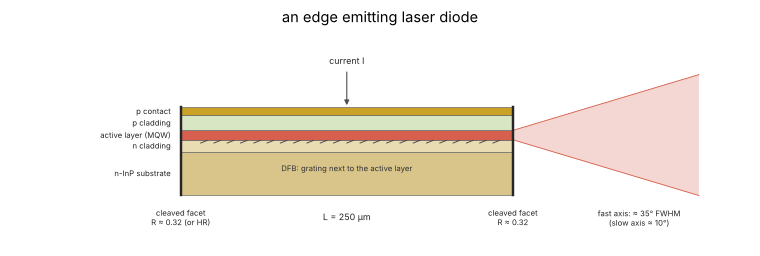

active volume 100 µm³, Gamma = 0.3, v_g = c/4.0
mirror loss 45 /cm (R = 0.32), internal loss 40 /cm, photon lifetime 1.57 ps
transparency 1.00e+18 cm⁻³, threshold 2.13e+18 cm⁻³, carrier lifetime at threshold 2.22 ns
threshold current 15.4 mA, slope 0.212 W/A per facet, differential quantum efficiency 53 % (both facets)


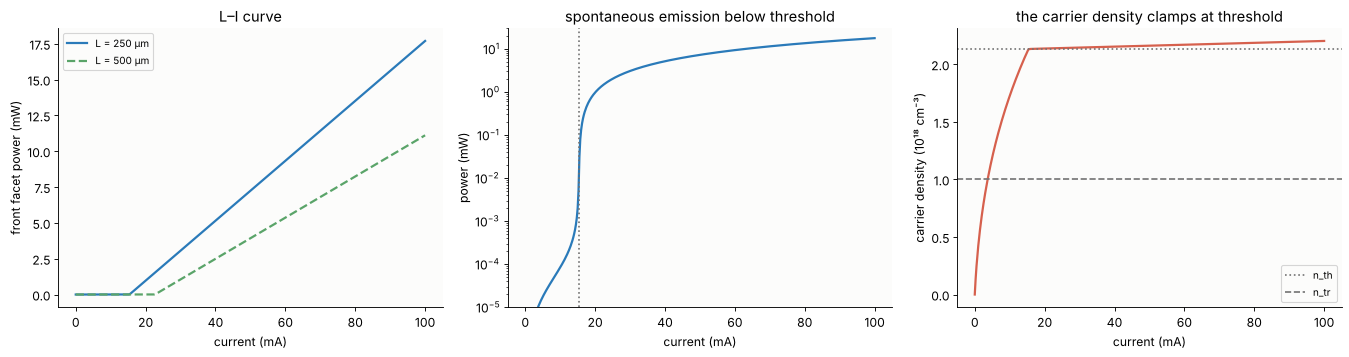

L = 500 µm: threshold 22.7 mA, slope 0.145 W/A


In [2]:
fig, ax = plt.subplots(figsize=(12, 3.6))
sketch.laser_layout(ax, "diode", title="an edge emitting laser diode")
plt.show()

dfb = L.DiodeLaser()
print("active volume {:.0f} µm³, Gamma = {:.1f}, v_g = c/{:.1f}".format(dfb.volume*1E18, dfb.confinement,
                                                                        L.C0/dfb.v_g))
print("mirror loss {:.0f} /cm (R = {:.2f}), internal loss {:.0f} /cm, photon lifetime {:.2f} ps".format(
    dfb.alpha_m/100, np.exp(-dfb.alpha_m*dfb.length), dfb.alpha_i/100, dfb.tau_p*1E12))
print("transparency {:.2e} cm⁻³, threshold {:.2e} cm⁻³, carrier lifetime at threshold {:.2f} ns".format(
    dfb.n_tr*1E-6, dfb.n_th*1E-6, dfb.carrier_lifetime()*1E9))
print("threshold current {:.1f} mA, slope {:.3f} W/A per facet, differential quantum efficiency {:.0f} % (both facets)".format(
    dfb.i_th*1E3, dfb.slope_efficiency(), 2*dfb.slope_efficiency()*L.Q_E/dfb.photon_energy*100))

I = np.linspace(0, 100E-3, 401)
P, n = dfb.li_curve(I)
long_cav = L.DiodeLaser(length=500E-6, alpha_m=np.log(1/0.32)/500E-6)
P_long, _ = long_cav.li_curve(I)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axes[0]
ax.plot(I*1E3, P*1E3, color=BLUE, lw=2, label="L = 250 µm")
ax.plot(I*1E3, P_long*1E3, color=GREEN, lw=2, ls="--", label="L = 500 µm")
ax.set_xlabel("current (mA)"); ax.set_ylabel("front facet power (mW)")
ax.set_title("L–I curve"); ax.legend(fontsize=9)
ax = axes[1]
ax.semilogy(I*1E3, P*1E3, color=BLUE, lw=2)
ax.axvline(dfb.i_th*1E3, color=GREY, ls=":")
ax.set_xlabel("current (mA)"); ax.set_ylabel("power (mW)")
ax.set_title("spontaneous emission below threshold")
ax.set_ylim(1E-5, 30)
ax = axes[2]
ax.plot(I*1E3, n*1E-24, color=RED, lw=2)
ax.axhline(dfb.n_th*1E-24, color=GREY, ls=":", label="n_th")
ax.axhline(dfb.n_tr*1E-24, color=GREY, ls="--", label="n_tr")
ax.set_xlabel("current (mA)"); ax.set_ylabel("carrier density (10¹⁸ cm⁻³)")
ax.set_title("the carrier density clamps at threshold"); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
print("L = 500 µm: threshold {:.1f} mA, slope {:.3f} W/A".format(long_cav.i_th*1E3, long_cav.slope_efficiency()))

Threshold is at 15.4 mA, the power then rises with 0.21 W/A per facet, a
differential quantum efficiency of 53 % for both facets together: almost
half the photons are lost inside, because the internal loss (free carrier
absorption, scattering) is as large as the mirror loss. Below threshold
the facet emits only the spontaneous emission that happens to go into the
mode, microwatts; the L–I curve on a log scale shows the kink of six
decades. A cavity twice as long has half the mirror loss: its threshold
density is lower, but its volume is twice as large, so its threshold
current is higher, and its slope smaller. Short cavities with high
reflectivity coatings on the rear facet are therefore the usual choice
for low threshold lasers; high power lasers use long cavities to spread
the heat.

## 2. The spectrum of Fabry–Perot and DFB lasers

A 250 µm Fabry–Perot cavity has modes every $v_g/2L$ = 150 GHz (1.2 nm at
1550 nm); the gain of the active layer is tens of nanometres wide and
nearly flat over many modes. All modes share the same carriers, and each
carries the spontaneous emission it gets, amplified by
$1/(1/\tau_p - G_m)$. Below threshold many modes glow; above threshold the
mode at the gain peak takes most of the power, but its neighbours, only
slightly below it in gain, keep a large share. A DFB grating selects one
mode by giving it a lower loss, a few percent of the total, and that mode
then suppresses the others by orders of magnitude (side mode suppression
ratio, SMSR). `dfb.mode_spectrum()` solves the steady state of the
multimode rate equations.

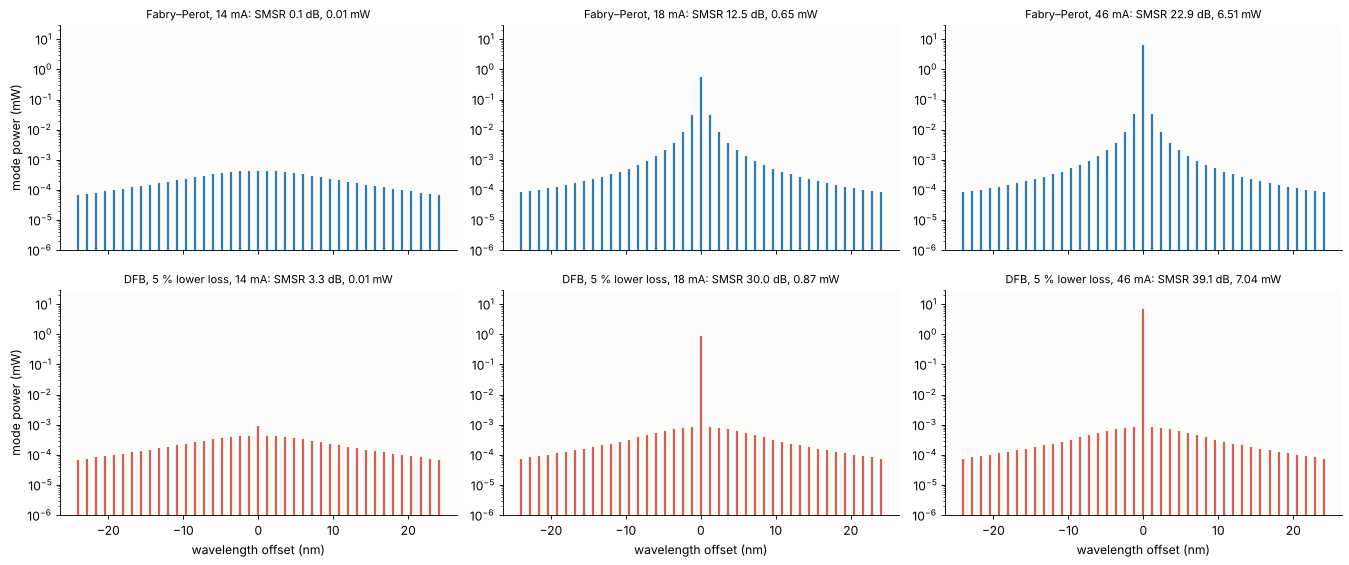

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(17, 7.2), sharex=True)
for col, I_x in enumerate((0.9*dfb.i_th, 1.2*dfb.i_th, 3*dfb.i_th)):
    for row, (name, sel, c) in enumerate((("Fabry–Perot", None, BLUE), ("DFB, 5 % lower loss", (0, 0.05), RED))):
        nu_m, P_m = dfb.mode_spectrum(I_x, n_modes=41, selection=sel)
        wl_m = -nu_m*(1.55E-6)**2/L.C0*1E9
        ax = axes[row, col]
        ax.vlines(wl_m, 1E-6, P_m*1E3, color=c, lw=2)
        ax.set_yscale("log"); ax.set_ylim(1E-6, 30)
        Ps = np.sort(P_m)
        ax.set_title(f"{name}, {I_x*1E3:.0f} mA: SMSR {10*np.log10(Ps[-1]/Ps[-2]):.1f} dB, "
                     f"{P_m.sum()*1E3:.2f} mW", fontsize=10)
        if col == 0:
            ax.set_ylabel("mode power (mW)")
for ax in axes[1]:
    ax.set_xlabel("wavelength offset (nm)")
plt.tight_layout()
plt.show()

Below threshold the Fabry–Perot spectrum follows the gain curve. At 1.2
times threshold the strongest mode carries only 18 times the power of
each neighbour and less than the sum of all the others, and even at three
times threshold the side modes are only 23 dB down. In a dispersive fibre each of these modes travels at its own
group velocity, and the power hops between them (mode partition noise),
which is why Fabry–Perot lasers are limited to short links or to the
1310 nm window. The DFB laser with a mode loss lower by 5 % has a side
mode suppression of 30 dB just above threshold and 39 dB at three times
threshold, and is the standard source of fibre links. (A real
DFB grating has two modes at the edges of its stop band; a quarter wave
phase shift in the grating, or an asymmetric facet coating, picks one of
them.)

## 3. Turn-on delay and relaxation oscillations

When the current jumps from $I_b$ below threshold to $I$ above, the
carriers first have to fill up to $n_{th}$; the light only appears after
the **turn-on delay**

$$t_d \approx \tau_e\ln\frac{I - I_b}{I - I_{th}},$$

with the carrier lifetime $\tau_e$ (for a constant lifetime). The photons
then overshoot and ring at the relaxation oscillation frequency, like the
spikes of the solid-state laser in notebook 142 (laser fundamentals), but
a thousand times faster, at gigahertz frequencies, damped within a
nanosecond.

from 0.0 I_th to 3 I_th: delay to half power  968 ps, estimate tau_e ln((I - I_b)/(I - I_th))  901 ps


from 0.5 I_th to 3 I_th: delay to half power  409 ps, estimate tau_e ln((I - I_b)/(I - I_th))  496 ps


from 0.9 I_th to 3 I_th: delay to half power  173 ps, estimate tau_e ln((I - I_b)/(I - I_th))  108 ps


from 1.3 I_th to 3 I_th: delay to half power   55 ps, estimate tau_e ln((I - I_b)/(I - I_th))    0 ps


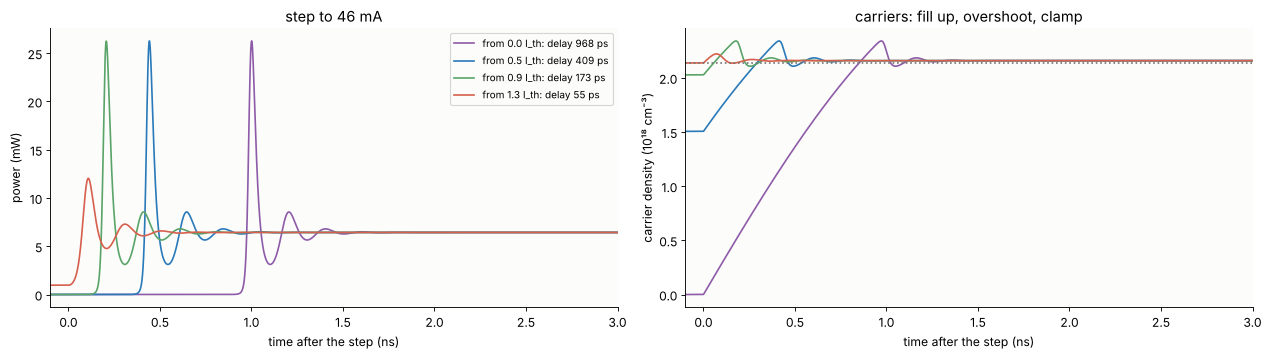

In [4]:
t = np.arange(0, 4E-9, 0.1E-12)
I_on = 3*dfb.i_th
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
for I_b, c in ((0.0, PURPLE), (0.5*dfb.i_th, BLUE), (0.9*dfb.i_th, GREEN), (1.3*dfb.i_th, RED)):
    t0 = 0.2E-9
    N, S, phi = dfb.simulate(t, np.where(t < t0, I_b, I_on))
    P_t = dfb.power(S)
    P_ss = dfb.power(dfb.steady_state(I_on)[1])
    k = np.nonzero(P_t > 0.5*P_ss)[0][0]
    t_d = t[k] - t0
    tau_e = dfb.carrier_lifetime()
    t_d_est = tau_e*np.log((I_on - I_b)/(I_on - dfb.i_th)) if I_b < dfb.i_th else 0.0
    axes[0].plot((t - t0)*1E9, P_t*1E3, color=c, lw=1.5, label=f"from {I_b/dfb.i_th:.1f} I_th: delay {t_d*1E12:.0f} ps")
    axes[1].plot((t - t0)*1E9, N/dfb.volume*1E-24, color=c, lw=1.5)
    print("from {:.1f} I_th to {:.0f} I_th: delay to half power {:4.0f} ps, estimate tau_e ln((I - I_b)/(I - I_th)) {:4.0f} ps".format(
        I_b/dfb.i_th, I_on/dfb.i_th, t_d*1E12, t_d_est*1E12))
axes[0].set_xlabel("time after the step (ns)"); axes[0].set_ylabel("power (mW)")
axes[0].set_title(f"step to {I_on*1E3:.0f} mA"); axes[0].legend(fontsize=9)
axes[0].set_xlim(-0.1, 3)
axes[1].axhline(dfb.n_th*1E-24, color=GREY, ls=":")
axes[1].set_xlabel("time after the step (ns)"); axes[1].set_ylabel("carrier density (10¹⁸ cm⁻³)")
axes[1].set_title("carriers: fill up, overshoot, clamp"); axes[1].set_xlim(-0.1, 3)
plt.tight_layout()
plt.show()

Starting from zero current the light comes 1 ns late, ten bits at
10 Gb/s; from 0.9 times threshold the delay shrinks to 170 ps, and from
above threshold only the 55 ps of the rise remain. The estimate with the
constant carrier lifetime of threshold gets the delays within 30 % from
below threshold; the true lifetime $n/R(n)$ changes with the density,
since $R = An + Bn^2 + Cn^3$. Directly modulated lasers
are therefore biased at or above threshold, at the price of light in the
zeros (a finite extinction ratio). The relaxation oscillations ring at
about 5 GHz here, with a first spike four times the final power; they are the
resonance that limits how fast the laser can be modulated.

## 4. Small-signal modulation response

A small sinusoidal current on top of the bias modulates the photon
number. Linearizing the rate equations around the steady state gives a
two-pole response with the relaxation oscillation frequency and damping,

$$\frac{\delta S(f)}{\delta S(0)} \approx \frac{f_R^2}{f_R^2 - f^2 - if\gamma/2\pi},\qquad
  f_R \approx \frac{1}{2\pi}\sqrt{\frac{G_NS}{\tau_p}} \propto \sqrt{I - I_{th}},$$

with the differential gain $G_N = \partial G/\partial N$. The damping
grows with $f_R^2$ through gain compression, $\gamma = Kf_R^2 + \gamma_0$,
which caps the 3 dB bandwidth at $2\sqrt2\pi/K$. `dfb.modulation_response()`
computes the response exactly from the Jacobian of the rate equations.

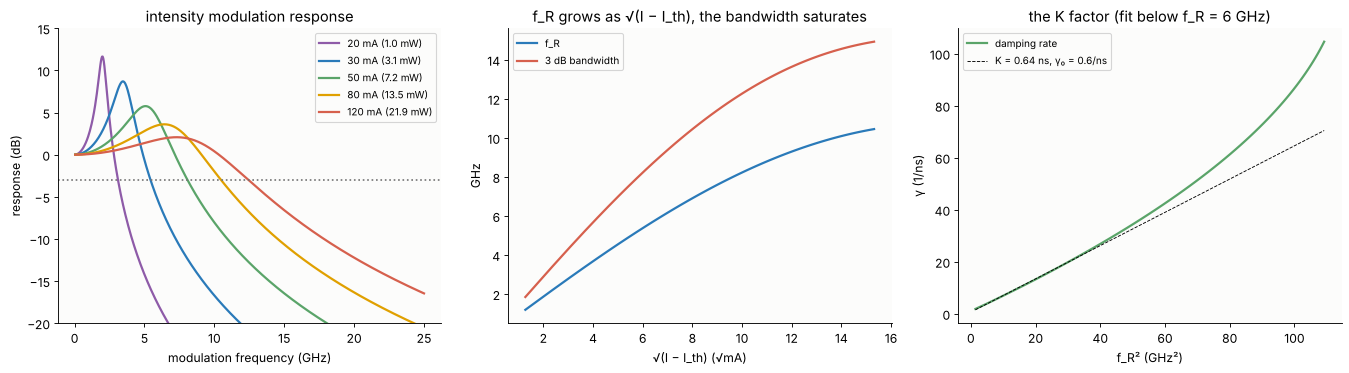

  20 mA: f_R =  2.0 GHz (sqrt(G_N S/tau_p)/2 pi =  2.0 GHz), damping  3.4/ns, 3 dB bandwidth  3.1 GHz
  50 mA: f_R =  5.3 GHz (sqrt(G_N S/tau_p)/2 pi =  5.5 GHz), damping 18.4/ns, 3 dB bandwidth  8.1 GHz
 120 mA: f_R =  8.4 GHz (sqrt(G_N S/tau_p)/2 pi =  9.6 GHz), damping 51.2/ns, 3 dB bandwidth 12.4 GHz
K factor 0.639 ns: maximum bandwidth 2 sqrt(2) pi/K = 13.9 GHz; largest computed 14.9 GHz


In [5]:
f = np.linspace(0.05E9, 25E9, 600)
currents = np.array([20, 30, 50, 80, 120])*1E-3
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for I_x, c in zip(currents, (PURPLE, BLUE, GREEN, ORANGE, RED)):
    H = dfb.modulation_response(f, I_x)
    axes[0].plot(f/1E9, 20*np.log10(np.abs(H)), color=c, lw=2,
                 label=f"{I_x*1E3:.0f} mA ({dfb.power(dfb.steady_state(I_x)[1])*1E3:.1f} mW)")
axes[0].axhline(-3, color=GREY, ls=":")
axes[0].set_ylim(-20, 15); axes[0].set_xlabel("modulation frequency (GHz)"); axes[0].set_ylabel("response (dB)")
axes[0].set_title("intensity modulation response"); axes[0].legend(fontsize=9)
I_sweep = np.linspace(17E-3, 250E-3, 60)
fR, gam, f3 = [], [], []
for I_x in I_sweep:
    a_, b_ = dfb.relaxation(I_x)
    fR.append(a_); gam.append(b_); f3.append(dfb.bandwidth_3db(I_x))
fR, gam, f3 = map(np.array, (fR, gam, f3))
axes[1].plot(np.sqrt((I_sweep - dfb.i_th)*1E3), fR/1E9, color=BLUE, lw=2, label="f_R")
axes[1].plot(np.sqrt((I_sweep - dfb.i_th)*1E3), f3/1E9, color=RED, lw=2, label="3 dB bandwidth")
axes[1].set_xlabel("√(I − I_th) (√mA)"); axes[1].set_ylabel("GHz")
axes[1].set_title("f_R grows as √(I − I_th), the bandwidth saturates"); axes[1].legend(fontsize=9)
lin = fR < 6E9
K, gamma0 = np.polyfit(fR[lin]**2, gam[lin], 1)
axes[2].plot(fR**2/1E18, gam/1E9, color=GREEN, lw=2, label="damping rate")
axes[2].plot(fR**2/1E18, (K*fR**2 + gamma0)/1E9, color="k", lw=0.8, ls="--",
             label=f"K = {K*1E9:.2f} ns, γ₀ = {gamma0/1E9:.1f}/ns")
axes[2].set_xlabel("f_R² (GHz²)"); axes[2].set_ylabel("γ (1/ns)")
axes[2].set_title("the K factor (fit below f_R = 6 GHz)"); axes[2].legend(fontsize=9)
plt.tight_layout()
plt.show()
G_N = dfb.confinement*dfb.v_g*dfb.a/dfb.volume
for I_x in (20E-3, 50E-3, 120E-3):
    N0, S0 = dfb.steady_state(I_x)
    print("{:4.0f} mA: f_R = {:4.1f} GHz (sqrt(G_N S/tau_p)/2 pi = {:4.1f} GHz), damping {:4.1f}/ns, 3 dB bandwidth {:4.1f} GHz".format(
        I_x*1E3, dfb.relaxation(I_x)[0]/1E9, np.sqrt(G_N*S0/dfb.tau_p)/(2*np.pi)/1E9,
        dfb.relaxation(I_x)[1]/1E9, dfb.bandwidth_3db(I_x)/1E9))
print("K factor {:.3f} ns: maximum bandwidth 2 sqrt(2) pi/K = {:.1f} GHz; largest computed {:.1f} GHz".format(
    K*1E9, 2*np.sqrt(2)*np.pi/K/1E9, f3.max()/1E9))

The response is flat at low frequencies, peaks at the relaxation
oscillation and falls at 40 dB per decade above it. At 20 mA, just above
threshold, the peak is sharp (2 GHz, a 3 dB bandwidth of 3 GHz); at
120 mA $f_R$ is 8.4 GHz and the bandwidth 12 GHz, with the peak almost
damped away. $f_R$ grows as $\sqrt{I - I_{th}}$ at first and then more
slowly, because gain compression lowers the differential gain at high
photon density. The damping follows $Kf_R^2$ with $K$ = 0.64 ns, which
caps the bandwidth near 14 GHz; the largest bandwidth computed is
15 GHz, at 250 mA, a current this laser would not survive. Lasers for 25 Gb/s and
beyond use short cavities, strained quantum wells with a larger
differential gain, and a detuned DFB grating.

## 5. Chirp under direct modulation

The carrier density changes the refractive index of the active layer as
well as its gain; the ratio of the two changes is the linewidth
enhancement factor $\alpha$ = 3 to 6. When the current is switched, the
carrier density overshoots and so does the frequency, by

$$\Delta\nu(t) = \frac{\alpha}{4\pi}\left(\frac{d\ln P}{dt} + \kappa P\right)$$

(Koch and Linke): a **transient chirp** on the edges, blue on rising and
red on falling ones, and an **adiabatic chirp** proportional to the power,
from gain compression, which keeps the carrier density of the ones a
little higher than that of the zeros. The coefficient $\kappa$ follows
from the rate equations, $\kappa = \epsilon\Gamma/(V\tau_ph\nu v_g\alpha_mf)$.
The model of notebook 120 (fibre link) so far had only the transient
term, with an assumed $\alpha_H$; the rate equations give both, and the
power waveform with its overshoot. The transmitter is biased at 25 mA
(2 mW) and switched to 65 mA (10.4 mW), an extinction ratio of 7 dB, at
10 Gb/s.

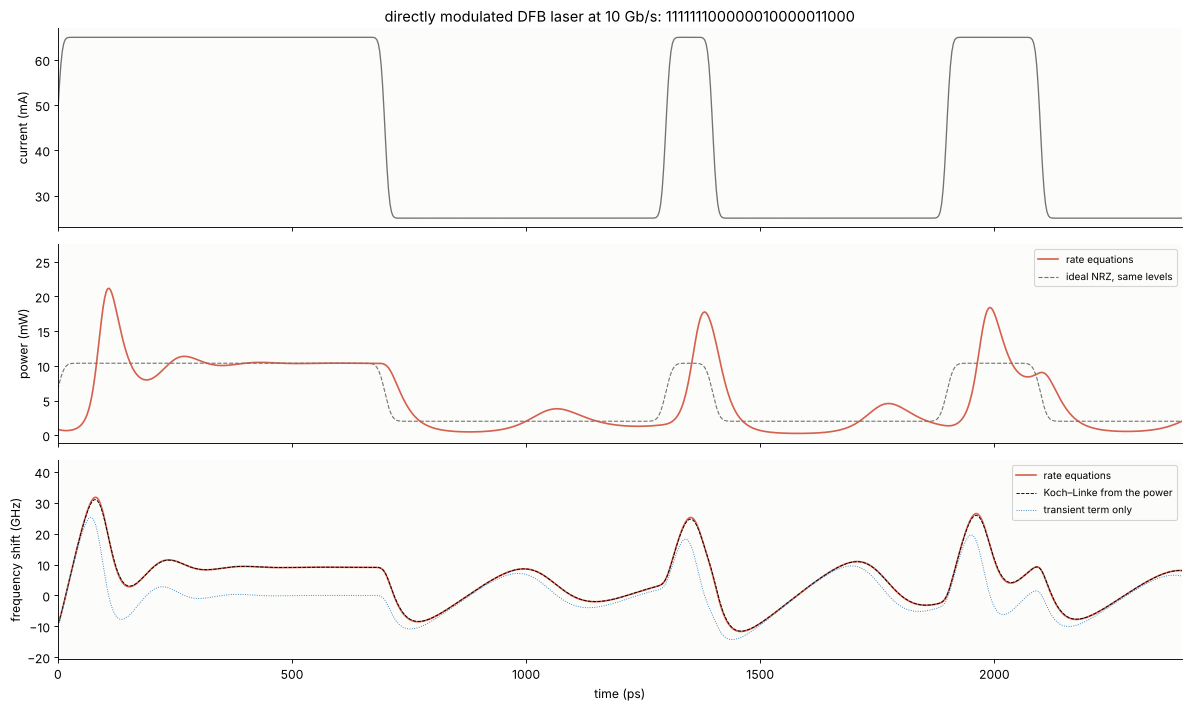

kappa = 2.21e+12 1/(W s): adiabatic chirp 0.88 GHz per mW
chirp from -14.7 to +40.8 GHz; ones minus zeros (adiabatic) 6.2 GHz, Koch-Linke 6.3 GHz
rms difference rate equations - Koch-Linke: 0.25 GHz
bias: f_R = 2.9 GHz, 3 dB bandwidth 4.4 GHz


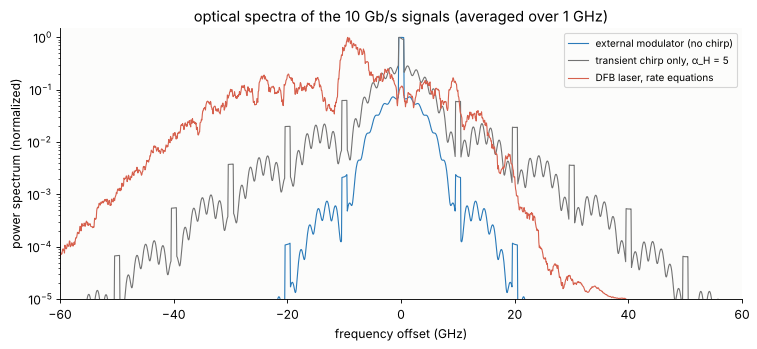

In [6]:
bits = fc.prbs(7)
B = 10.0
i_bias, i_mod = 25E-3, 40E-3
t_ps, A_dml, I_drive = dfb.nrz(bits, B, i_bias, i_mod, samples_per_bit=32)
P_dml = np.abs(A_dml)**2*1E-3                         # W
dt = (t_ps[1] - t_ps[0])*1E-12
nu_dml = -np.gradient(np.unwrap(np.angle(A_dml)), dt)/(2*np.pi)
nu_kl = dfb.alpha/(4*np.pi)*(np.gradient(np.log(P_dml), dt) + dfb.kappa*P_dml)
nu_tr_only = dfb.alpha/(4*np.pi)*np.gradient(np.log(P_dml), dt)
P_1, P_0 = dfb.li_curve([i_bias + i_mod, i_bias])[0]
_, A_old = fc.nrz(bits, B, samples_per_bit=32, p1=P_1*1E3, extinction=P_1/P_0, alpha_h=dfb.alpha)
nu_old = -np.gradient(np.unwrap(np.angle(A_old)), dt)/(2*np.pi)

T_bit = 1E3/B
fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
axes[0].plot(t_ps, I_drive*1E3, color=GREY, lw=1.2)
axes[0].set_ylabel("current (mA)")
axes[0].set_title("directly modulated DFB laser at 10 Gb/s: " + "".join(map(str, bits[:24])))
axes[1].plot(t_ps, P_dml*1E3, color=RED, lw=1.5, label="rate equations")
axes[1].plot(t_ps, np.abs(A_old)**2, color=GREY, lw=1, ls="--", label="ideal NRZ, same levels")
axes[1].set_ylabel("power (mW)"); axes[1].legend(fontsize=9, loc="upper right")
axes[2].plot(t_ps, nu_dml/1E9, color=RED, lw=1.5, label="rate equations")
axes[2].plot(t_ps, nu_kl/1E9, color="k", lw=0.8, ls="--", label="Koch–Linke from the power")
axes[2].plot(t_ps, nu_tr_only/1E9, color=BLUE, lw=0.8, ls=":", label="transient term only")
axes[2].set_ylabel("frequency shift (GHz)"); axes[2].set_xlabel("time (ps)")
axes[2].legend(fontsize=9, loc="upper right")
axes[2].set_xlim(0, 24*T_bit)
plt.tight_layout()
plt.show()

ones = np.repeat(bits, 32) == 1
centre = (np.arange(len(t_ps)) % 32 > 12) & (np.arange(len(t_ps)) % 32 < 20)
settled = centre & (np.repeat(bits, 32) == np.repeat(np.roll(bits, 1), 32))
print("kappa = {:.2e} 1/(W s): adiabatic chirp {:.2f} GHz per mW".format(dfb.kappa, dfb.alpha/(4*np.pi)*dfb.kappa*1E-3/1E9))
print("chirp from {:+.1f} to {:+.1f} GHz; ones minus zeros (adiabatic) {:.1f} GHz, Koch-Linke {:.1f} GHz".format(
    nu_dml.min()/1E9, nu_dml.max()/1E9,
    (nu_dml[settled & ones].mean() - nu_dml[settled & ~ones].mean())/1E9,
    (nu_kl[settled & ones].mean() - nu_kl[settled & ~ones].mean())/1E9))
print("rms difference rate equations - Koch-Linke: {:.2f} GHz".format(np.sqrt(np.mean((nu_dml - nu_kl)**2))/1E9))
print("bias: f_R = {:.1f} GHz, 3 dB bandwidth {:.1f} GHz".format(dfb.relaxation(i_bias)[0]/1E9,
                                                                 dfb.bandwidth_3db(i_bias)/1E9))

# spectra
def spectrum(A, smooth_ghz=1.0):
    """power spectrum, averaged over about 1 GHz (the PRBS pattern makes lines 79 MHz apart)"""
    S = np.fft.fftshift(np.abs(np.fft.fft(A))**2)
    k = max(int(smooth_ghz*1E9*len(A)*dt), 1)
    S = np.convolve(S, np.ones(k)/k, "same")
    return S/S.max()


f_spec = np.fft.fftshift(np.fft.fftfreq(len(t_ps), dt))
fig, ax = plt.subplots(figsize=(11, 4.4))
_, A_ext = fc.nrz(bits, B, samples_per_bit=32, p1=1.0)
ax.semilogy(f_spec/1E9, spectrum(A_ext), color=BLUE, lw=1, label="external modulator (no chirp)")
ax.semilogy(f_spec/1E9, spectrum(A_old), color=GREY, lw=1, label="transient chirp only, α_H = 5")
ax.semilogy(f_spec/1E9, spectrum(A_dml), color=RED, lw=1, label="DFB laser, rate equations")
ax.set_xlim(-60, 60); ax.set_ylim(1E-5, 1.5)
ax.set_xlabel("frequency offset (GHz)"); ax.set_ylabel("power spectrum (normalized)")
ax.set_title("optical spectra of the 10 Gb/s signals (averaged over 1 GHz)")
ax.legend(fontsize=9)
plt.show()

The rate equations show what the simple model left out. The power
overshoots at every rising edge and rings at the relaxation frequency
(4.4 GHz bandwidth at this bias, below the 7 GHz a 10 Gb/s signal needs).
The frequency jumps by up to +41 GHz on rising edges, and the ones sit
about 6 GHz above the zeros: the adiabatic chirp of 0.88 GHz per mW. The
Koch–Linke formula, evaluated with the simulated power, reproduces the
chirp to within a few hundred MHz; the transient term alone misses the
offset between ones and zeros. The optical spectrum of the directly
modulated laser is several times wider than that of an external
modulator and lopsided: the zeros sit to the red of the ones, and the
carrier undershoot after each falling edge spreads the spectrum far
to the red. At 1550 nm, where the fibre disperses these frequencies, this chirp
limits a directly modulated 10 Gb/s link to about 10 km (notebook 120,
fibre link).

## 6. Relative intensity noise

Spontaneous emission adds photons with random phases, and recombination
and injection are shot noise processes. In the rate equations these are
Langevin forces with the correlations $\langle F_SF_S\rangle = 2R_{sp}S$,
$\langle F_NF_N\rangle = 2(R_{sp}S + VR)$ and
$\langle F_SF_N\rangle = -2R_{sp}S$. The laser filters them through the
same response as the modulation current: the **relative intensity noise**
$\mathrm{RIN}(f) = S_{\delta P}(f)/P^2$ peaks at the relaxation oscillation
and falls steeply with the power. `dfb.rin()` evaluates it from the
linearized rate equations; `dfb.simulate(noise=True)` integrates the
rate equations with the forces, for a check.

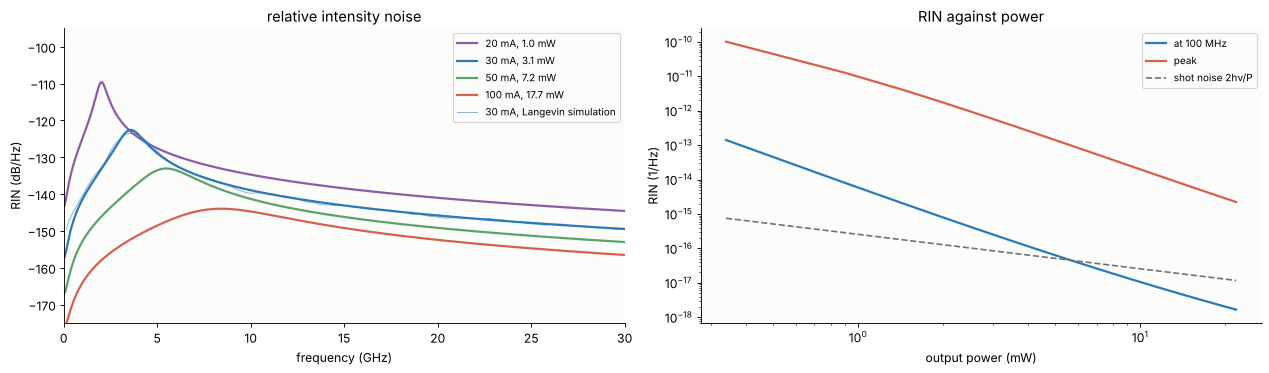

30 mA: relative variance of the photon number: simulation 1.14e-03, integral of RIN 1.16e-03
  20 mA: RIN -141.9 dB/Hz at 100 MHz, peak -109.6 dB/Hz; shot noise -155.8 dB/Hz
  30 mA: RIN -156.2 dB/Hz at 100 MHz, peak -122.6 dB/Hz; shot noise -160.8 dB/Hz
 100 mA: RIN -175.7 dB/Hz at 100 MHz, peak -144.0 dB/Hz; shot noise -168.4 dB/Hz


In [7]:
f_r = np.linspace(0.05E9, 30E9, 600)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for I_x, c in zip((20E-3, 30E-3, 50E-3, 100E-3), (PURPLE, BLUE, GREEN, RED)):
    axes[0].plot(f_r/1E9, 10*np.log10(dfb.rin(f_r, I_x)), color=c, lw=2,
                 label=f"{I_x*1E3:.0f} mA, {dfb.power(dfb.steady_state(I_x)[1])*1E3:.1f} mW")
# Langevin simulation at 30 mA
I_n = 30E-3
dt_n = 0.25E-12
t_n = np.arange(0, 8E-9, dt_n)
N_n, S_n, _ = dfb.simulate(t_n, I_n, noise=True, rng=7, realizations=48)
x = S_n[:, int(1E-9/dt_n):]
x = x - x.mean(axis=1, keepdims=True)
_, S0_n = dfb.steady_state(I_n)
nseg = x.shape[1]
win = np.hanning(nseg)
psd = np.mean(np.abs(np.fft.rfft(x*win, axis=1))**2, axis=0)*dt_n/np.sum(win**2)*2/S0_n**2
f_psd = np.fft.rfftfreq(nseg, dt_n)
kern = np.ones(9)/9
axes[0].plot(f_psd[1:]/1E9, 10*np.log10(np.convolve(psd, kern, "same")[1:]), color=BLUE, lw=0.8, alpha=0.6,
             label="30 mA, Langevin simulation")
axes[0].set_xlim(0, 30); axes[0].set_ylim(-175, -95)
axes[0].set_xlabel("frequency (GHz)"); axes[0].set_ylabel("RIN (dB/Hz)")
axes[0].set_title("relative intensity noise"); axes[0].legend(fontsize=9)
I_sw = np.linspace(17E-3, 120E-3, 40)
P_sw = dfb.power(np.array([dfb.steady_state(i)[1] for i in I_sw]))
rin_lf = np.array([dfb.rin(0.1E9, i)[0] for i in I_sw])
rin_pk = np.array([dfb.rin(np.linspace(0.1E9, 30E9, 300), i).max() for i in I_sw])
axes[1].loglog(P_sw*1E3, rin_lf, color=BLUE, lw=2, label="at 100 MHz")
axes[1].loglog(P_sw*1E3, rin_pk, color=RED, lw=2, label="peak")
axes[1].loglog(P_sw*1E3, 2*dfb.photon_energy/P_sw, color=GREY, lw=1.5, ls="--", label="shot noise 2hν/P")
axes[1].set_xlabel("output power (mW)"); axes[1].set_ylabel("RIN (1/Hz)")
axes[1].set_title("RIN against power"); axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()
f_band = 20E9
rel_var_sim = np.var(S_n[:, int(1E-9/dt_n):])/S0_n**2
f_int = np.linspace(0, 500E9, 50001)
print("30 mA: relative variance of the photon number: simulation {:.2e}, integral of RIN {:.2e}".format(
    rel_var_sim, np.trapezoid(dfb.rin(f_int, I_n), f_int)))
for i_x in (20E-3, 30E-3, 100E-3):
    print("{:4.0f} mA: RIN {:6.1f} dB/Hz at 100 MHz, peak {:6.1f} dB/Hz; shot noise {:6.1f} dB/Hz".format(
        i_x*1E3, 10*np.log10(dfb.rin(0.1E9, i_x)[0]), 10*np.log10(dfb.rin(np.linspace(0.1E9, 30E9, 300), i_x).max()),
        10*np.log10(2*dfb.photon_energy/dfb.power(dfb.steady_state(i_x)[1]))))

The simulation with Langevin forces follows the linearized RIN, and its
variance agrees with the integral of the spectrum within 2 %. The RIN of
this laser peaks at −110 dB/Hz at 1 mW, just above threshold, and at
−144 dB/Hz at 18 mW; at low frequencies it falls from −142 dB/Hz at
1 mW to −176 dB/Hz at 18 mW, roughly as $P^{-3}$. Above about 6 mW the
low frequency RIN falls below the shot noise $2h\nu/P$ of the output
itself (which `rin()` adds with `shot_noise=True`). In a link the RIN adds a noise current
$\sigma^2 = \mathrm{RIN}\,(RP)^2\Delta f$ that grows with the received
power, so it sets a ceiling on the Q factor however strong the signal;
notebook 120 (fibre link) includes it.

## 7. Linewidth

The phase of the field diffuses with every spontaneously emitted photon:
$\langle F_\phi F_\phi\rangle = R_{sp}/2S$. That alone gives a Lorentzian
line of width $R_{sp}/(4\pi S)$, the Schawlow–Townes linewidth of notebook
142 (laser fundamentals). Each spontaneous photon also perturbs the photon
number; the carriers respond, and through $\alpha$ the phase follows.
Integrated over the relaxation oscillation this adds $\alpha^2$ times the
direct contribution (Henry):

$$\Delta\nu = \frac{R_{sp}}{4\pi S}(1 + \alpha^2).$$

The simulation records the phase of many noisy runs; its variance grows as
$\langle\Delta\phi^2(\tau)\rangle = 2\pi\Delta\nu\,\tau$ for delays
longer than the relaxation oscillation.

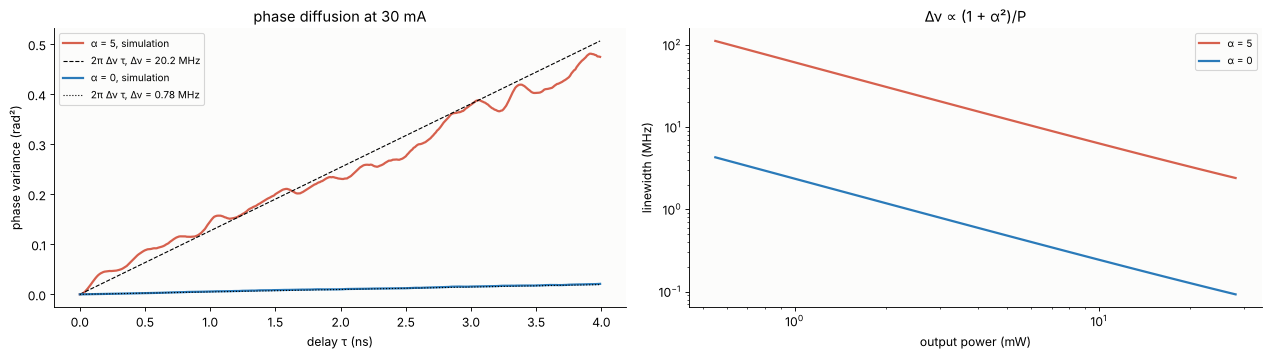

30 mA: linewidth from the simulation 17.9 MHz (Henry 20.2 MHz); with alpha = 0 0.78 MHz (0.78 MHz)
  20 mA,   1.0 mW: linewidth  63.4 MHz
  50 mA,   7.2 mW: linewidth   8.7 MHz
 100 mA,  17.7 mW: linewidth   3.7 MHz


In [8]:
I_l = 30E-3
dt_l = 0.25E-12
t_l = np.arange(0, 6E-9, dt_l)
_, _, phi_l = dfb.simulate(t_l, I_l, noise=True, rng=11, realizations=256)
no_alpha = L.DiodeLaser(alpha=0.0)
_, _, phi_0 = no_alpha.simulate(t_l, I_l, noise=True, rng=11, realizations=256)
k0 = int(1E-9/dt_l)
lags = np.arange(1, int(4E-9/dt_l), 40)
var_l = np.array([np.var(phi_l[:, k0 + k] - phi_l[:, k0]) for k in lags])
var_0 = np.array([np.var(phi_0[:, k0 + k] - phi_0[:, k0]) for k in lags])
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
ax = axes[0]
ax.plot(lags*dt_l*1E9, var_l, color=RED, lw=2, label="α = 5, simulation")
ax.plot(lags*dt_l*1E9, 2*np.pi*dfb.linewidth(I_l)*lags*dt_l, color="k", lw=1, ls="--",
        label=f"2π Δν τ, Δν = {dfb.linewidth(I_l)/1E6:.1f} MHz")
ax.plot(lags*dt_l*1E9, var_0, color=BLUE, lw=2, label="α = 0, simulation")
ax.plot(lags*dt_l*1E9, 2*np.pi*no_alpha.linewidth(I_l)*lags*dt_l, color="k", lw=1, ls=":",
        label=f"2π Δν τ, Δν = {no_alpha.linewidth(I_l)/1E6:.2f} MHz")
ax.set_xlabel("delay τ (ns)"); ax.set_ylabel("phase variance (rad²)")
ax.set_title(f"phase diffusion at {I_l*1E3:.0f} mA"); ax.legend(fontsize=9)
ax = axes[1]
I_lw = np.linspace(18E-3, 150E-3, 40)
P_lw = dfb.power(np.array([dfb.steady_state(i)[1] for i in I_lw]))
ax.loglog(P_lw*1E3, [dfb.linewidth(i)/1E6 for i in I_lw], color=RED, lw=2, label="α = 5")
ax.loglog(P_lw*1E3, [no_alpha.linewidth(i)/1E6 for i in I_lw], color=BLUE, lw=2, label="α = 0")
ax.set_xlabel("output power (mW)"); ax.set_ylabel("linewidth (MHz)")
ax.set_title("Δν ∝ (1 + α²)/P"); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
sel = lags*dt_l > 1E-9
slope_l = np.polyfit(lags[sel]*dt_l, var_l[sel], 1)[0]/(2*np.pi)
slope_0 = np.polyfit(lags[sel]*dt_l, var_0[sel], 1)[0]/(2*np.pi)
print("30 mA: linewidth from the simulation {:.1f} MHz (Henry {:.1f} MHz); with alpha = 0 {:.2f} MHz ({:.2f} MHz)".format(
    slope_l/1E6, dfb.linewidth(I_l)/1E6, slope_0/1E6, no_alpha.linewidth(I_l)/1E6))
for i_x in (20E-3, 50E-3, 100E-3):
    print("{:4.0f} mA, {:5.1f} mW: linewidth {:5.1f} MHz".format(i_x*1E3, dfb.power(dfb.steady_state(i_x)[1])*1E3,
                                                               dfb.linewidth(i_x)/1E6))

The phase variance of the simulated runs grows linearly with the delay,
with the slope of Henry's formula within the statistical scatter of 256
runs (about 10 %), and with $\alpha = 0$ it is 26 times smaller. The linewidth falls inversely with the power, from about 60 MHz
at 1 mW to a few MHz at 15 mW; real DFB lasers reach 1 to 10 MHz, and
their linewidth eventually stops falling (gain compression, side modes,
technical noise). Coherent communication and FMCW LiDAR (notebook 131,
FMCW LiDAR) need 100 kHz or less, which takes long external cavities or
narrow linewidth designs with a lower $\alpha$ and a higher Q.

## Summary

- **Threshold:** $\Gamma a(n_{th} - n_{tr}) = \alpha_m + \alpha_i$;
  15.4 mA and 0.21 W/A per facet for the 250 µm DFB laser; the carrier
  density clamps above threshold.
- **Spectrum:** a Fabry–Perot laser runs on several modes 150 GHz apart,
  even far above threshold; a DFB grating with a few percent loss
  difference gives a side mode suppression of 30 to 45 dB.
- **Dynamics:** a turn-on delay of up to a nanosecond from zero bias, and
  relaxation oscillations at gigahertz; the modulation bandwidth grows as
  $\sqrt{I - I_{th}}$, limited by damping through the K factor.
- **Chirp:** $\Delta\nu = (\alpha/4\pi)(d\ln P/dt + \kappa P)$, here up to
  +41 GHz on rising edges and 0.9 GHz/mW adiabatic chirp.
- **Noise:** RIN peaks at $f_R$ and falls steeply with power, from
  −110 dB/Hz near threshold to −144 dB/Hz at 18 mW; the linewidth
  $R_{sp}(1 + \alpha^2)/(4\pi S)$ is megahertz, 26 times wider than without
  the $\alpha$ factor.

In [9]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 21 s


## References

- G. P. Agrawal, *Fiber-Optic Communication Systems*, 4th ed., Wiley
  (2010), chapter 3.
- L. A. Coldren, S. W. Corzine and M. L. Mashanovitch, *Diode Lasers and
  Photonic Integrated Circuits*, 2nd ed., Wiley (2012), chapters 2, 5, 6
  and appendix 13.
- C. H. Henry, "Theory of the linewidth of semiconductor lasers", IEEE J.
  Quantum Electron. 18, 259–264 (1982).
- T. L. Koch and R. A. Linke, "Effect of nonlinear gain reduction on
  semiconductor laser wavelength chirping", Appl. Phys. Lett. 48,
  613–615 (1986).
- K. Petermann, *Laser Diode Modulation and Noise*, Kluwer (1988).
- B. E. A. Saleh and M. C. Teich, *Fundamentals of Photonics*, 3rd ed.,
  Wiley (2019), chapter 18.